# CoOp Prompt Tuning (Context Optimization) for Pet Breed Classification

Dự án này triển khai phương pháp **Prompt Tuning (CoOp: Context Optimization)** để phân loại 37 giống chó/mèo từ tập dữ liệu **Oxford-IIIT Pet**.

### 1. Ý tưởng cốt lõi của CoOp (Context Optimization)
* Thay vì thiết kế các câu prompt thủ công dạng cứng như `"Picture of a pet with breed: {breed}"`, CoOp **học các vector ngữ cảnh liên tục (continuous context vectors)** trực tiếp từ dữ liệu trainval.
* **Cấu trúc Prompt:**
  $$t_i = [\text{SOS}, v_1, v_2, \dots, v_M, c_i, \text{EOS}, \text{PAD}, \dots]$$
  Trong đó:
  - $v_1, \dots, v_M$ là các vector embedding liên tục đóng vai trò là prompt (mặc định chọn $M = 4$ tokens).
  - $c_i$ là token embedding của tên giống vật nuôi (class name).
  - Các vector $v$ là các tham số **có thể huấn luyện** (learnable parameters).
* **Đóng băng CLIP:** Toàn bộ các trọng số của bộ mã hóa hình ảnh và bộ mã hóa văn bản của CLIP đều được đóng băng. Chỉ có duy nhất các vector ngữ cảnh $v_1, \dots, v_M$ là được cập nhật qua quá trình huấn luyện bằng lan truyền ngược.

### 2. Thiết lập bài toán (Full Trainval Split)
* Toàn bộ tập dữ liệu **trainval** (3680 ảnh) được chia làm 2 phần:
  - **Train Set (90%):** Dùng làm tập huấn luyện.
  - **Validation Set (10%):** Dùng để tối ưu tham số và early stopping.
* **Test Set:** Toàn bộ 3,669 ảnh trong tập **test** để làm Query/Test set đánh giá.


In [1]:
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from transformers import CLIPModel, CLIPProcessor
import PIL.Image
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Thiết lập thiết bị chạy tự động (MPS cho macOS, CUDA cho GPU, hoặc CPU)
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    elif torch.backends.mps.is_available():
        return torch.device("mps")
    else:
        return torch.device("cpu")

device = get_device()
print(f"Sử dụng thiết bị phần cứng: {device}")

# Hàm thiết lập seed để đảm bảo tính tái lập kết quả
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Sử dụng thiết bị phần cứng: mps


In [2]:
class_names = [
    'Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 
    'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 
    'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 
    'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 
    'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 
    'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 
    'Wheaten Terrier', 'Yorkshire Terrier'
]

class_to_species = {
    # Cats
    'Abyssinian': 'cat', 'Bengal': 'cat', 'Birman': 'cat', 'Bombay': 'cat',
    'British Shorthair': 'cat', 'Egyptian Mau': 'cat', 'Maine Coon': 'cat',
    'Persian': 'cat', 'Ragdoll': 'cat', 'Russian Blue': 'cat', 'Siamese': 'cat',
    'Sphynx': 'cat',
    # Dogs
    'American Bulldog': 'dog', 'American Pit Bull Terrier': 'dog', 'Basset Hound': 'dog',
    'Beagle': 'dog', 'Boxer': 'dog', 'Chihuahua': 'dog', 'English Cocker Spaniel': 'dog', 
    'English Setter': 'dog', 'German Shorthaired': 'dog', 'Great Pyrenees': 'dog',
    'Havanese': 'dog', 'Japanese Chin': 'dog', 'Keeshond': 'dog', 'Leonberger': 'dog',
    'Miniature Pinscher': 'dog', 'Newfoundland': 'dog', 'Pomeranian': 'dog', 'Pug': 'dog',
    'Saint Bernard': 'dog', 'Samoyed': 'dog', 'Scottish Terrier': 'dog', 'Shiba Inu': 'dog',
    'Staffordshire Bull Terrier': 'dog', 'Wheaten Terrier': 'dog', 'Yorkshire Terrier': 'dog',
}


In [3]:
print("Tải CLIP Model và Processor...")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model.eval()

# Thiết lập đường dẫn load cache đặc trưng hình ảnh (Sử dụng đường dẫn tương đối ../../dataset)
trainval_features_path = "../../dataset/trainval_features.pt"
trainval_labels_path = "../../dataset/trainval_labels.pt"
test_features_path = "../../dataset/test_features.pt"
test_labels_path = "../../dataset/test_labels.pt"

# Nạp đặc trưng hình ảnh
if (os.path.exists(trainval_features_path) and os.path.exists(trainval_labels_path) and
    os.path.exists(test_features_path) and os.path.exists(test_labels_path)):
    print("Nạp các đặc trưng hình ảnh đã được cache thành công!")
    trainval_features = torch.load(trainval_features_path)
    trainval_labels = torch.load(trainval_labels_path)
    test_features = torch.load(test_features_path)
    test_labels = torch.load(test_labels_path)
    print(f"Kích thước trainval: {trainval_features.shape}")
    print(f"Kích thước test: {test_features.shape}")
else:
    raise FileNotFoundError("Không tìm thấy các file đặc trưng cache trong thư mục dataset/! Vui lòng chạy file extract_features.py trước.")


Tải CLIP Model và Processor...
Nạp các đặc trưng hình ảnh đã được cache thành công!
Kích thước trainval: torch.Size([3680, 512])
Kích thước test: torch.Size([3669, 512])


In [4]:
# Hàm phân chia trainval thành 90% train và 10% validation theo phân tầng (stratified)
def get_train_val_split(features, labels, train_ratio=0.9, seed=42):
    set_seed(seed)
    num_classes = 37
    train_idx = []
    val_idx = []
    
    for c in range(num_classes):
        class_indices = (labels == c).nonzero(as_tuple=True)[0]
        shuffled = class_indices[torch.randperm(len(class_indices))]
        
        split_point = int(len(class_indices) * train_ratio)
        train_idx.append(shuffled[:split_point])
        val_idx.append(shuffled[split_point:])
        
    train_idx = torch.cat(train_idx)
    val_idx = torch.cat(val_idx)
    
    return features[train_idx], labels[train_idx], features[val_idx], labels[val_idx]

train_features, train_labels, val_features, val_labels = get_train_val_split(
    trainval_features, trainval_labels, train_ratio=0.9, seed=42
)
print("Kích thước tập Train (90%):", train_features.shape)
print("Kích thước tập Validation (10%):", val_features.shape)


Kích thước tập Train (90%): torch.Size([3310, 512])
Kích thước tập Validation (10%): torch.Size([370, 512])


In [5]:
# Hàm sinh ra các input_ids chèn các token ngữ cảnh liên tục đặc biệt
def construct_coop_input_ids(class_names, processor, num_ctx=4):
    coop_input_ids = []
    for name in class_names:
        # Tokenize tên class name
        tokens = processor(text=name, return_tensors="pt")["input_ids"][0]
        
        sos = tokens[0:1]         # SOS token
        name_tokens = tokens[1:-1] # Tên giống
        eos = tokens[-1:]         # EOS token
        
        # Các token ngữ cảnh liên tục liên tiếp: 49400, 49401, ...
        ctx_tokens = torch.tensor([49400 + i for i in range(num_ctx)])
        
        # Kết hợp các token: [SOS, CTX1, CTX2, ..., NAME, EOS]
        seq = torch.cat([sos, ctx_tokens, name_tokens, eos])
        
        # Pad đến độ dài 77
        padding_len = 77 - len(seq)
        if padding_len > 0:
            pad = torch.zeros(padding_len, dtype=torch.long)
            seq = torch.cat([seq, pad])
        else:
            seq = seq[:77]
            seq[-1] = eos[0]
            
        coop_input_ids.append(seq)
    return torch.stack(coop_input_ids)

coop_input_ids = construct_coop_input_ids(class_names, processor, num_ctx=4).to(device)
print("Kích thước coop_input_ids:", coop_input_ids.shape)


Kích thước coop_input_ids: torch.Size([37, 77])


In [6]:
# Định nghĩa lớp phân loại CoOp (Context Optimization)
class CoOpClassifier(nn.Module):
    def __init__(self, clip_model, num_classes=37, num_ctx=4):
        super().__init__()
        self.clip_model = clip_model
        self.num_classes = num_classes
        self.num_ctx = num_ctx
        
        # Khởi tạo 4 vector ngữ cảnh liên tục
        self.ctx = nn.Parameter(torch.randn(num_ctx, 512) * 0.02)
        
        # Lưu hàm forward gốc
        self.orig_forward = clip_model.text_model.embeddings.token_embedding.forward
        
        # Đè phương thức forward của embedding
        def custom_embedding_forward(input_ids, *args, **kwargs):
            embeds = self.orig_forward(input_ids, *args, **kwargs).clone()
            for i in range(self.num_ctx):
                mask = (input_ids == (49400 + i))
                if mask.any():
                    embeds[mask] = self.ctx[i].to(embeds.dtype)
            return embeds
            
        self.clip_model.text_model.embeddings.token_embedding.forward = custom_embedding_forward
        
    def get_text_features(self, input_ids):
        text_features = self.clip_model.get_text_features(input_ids=input_ids)
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)
        return text_features
        
    def forward(self, image_features, input_ids):
        text_features = self.get_text_features(input_ids)
        logits = (image_features @ text_features.t()) * self.clip_model.logit_scale.exp()
        return logits


In [7]:
# Hàm huấn luyện CoOp Prompt Tuning
def train_coop(support_feats, support_lbls, val_feats, val_lbls, coop_input_ids, epochs=50, lr=0.002):
    model_coop = CoOpClassifier(model, num_classes=37, num_ctx=4).to(device)
    
    # Chỉ tối ưu self.ctx
    optimizer = torch.optim.AdamW([model_coop.ctx], lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    
    dataset = TensorDataset(support_feats, support_lbls)
    batch_size = min(256, len(support_feats))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    best_val_acc = 0.0
    best_weights = None
    
    for epoch in range(epochs):
        model_coop.train()
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            
            optimizer.zero_grad()
            outputs = model_coop(x_batch, coop_input_ids)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            
        # Đánh giá trên tập Validation
        model_coop.eval()
        with torch.no_grad():
            val_outputs = model_coop(val_feats.to(device), coop_input_ids)
            val_preds = val_outputs.argmax(dim=-1)
            val_acc = (val_preds == val_lbls.to(device)).float().mean().item()
            
        # Early Stopping
        if val_acc >= best_val_acc:
            best_val_acc = val_acc
            best_weights = model_coop.state_dict().copy()
            
    if best_weights is not None:
        model_coop.load_state_dict(best_weights)
        
    return model_coop


In [8]:
# Huấn luyện CoOp (50 epochs)
print("1. Huấn luyện CoOp Prompt Tuning trên tập Train (90% trainval) và validate trên 10% val...")
model_coop = train_coop(
    train_features, train_labels, val_features, val_labels, coop_input_ids, epochs=50, lr=0.002
)

print("\n2. Chạy đánh giá trên tập Test...")
model_coop.eval()
with torch.no_grad():
    logits_test = model_coop(test_features.to(device), coop_input_ids)
    preds_test = logits_test.argmax(dim=-1)
    acc_coop = (preds_test == test_labels.to(device)).float().mean().item() * 100
print(f"-> Độ chính xác CoOp Prompt Tuning: {acc_coop:.2f}%")


1. Huấn luyện CoOp Prompt Tuning trên tập Train (90% trainval) và validate trên 10% val...

2. Chạy đánh giá trên tập Test...
-> Độ chính xác CoOp Prompt Tuning: 90.98%


TÓM TẮT ĐỘ CHÍNH XÁC PHÂN LOẠI:
--------------------------------------------------
CoOp Prompt Tuning:              90.98%
--------------------------------------------------


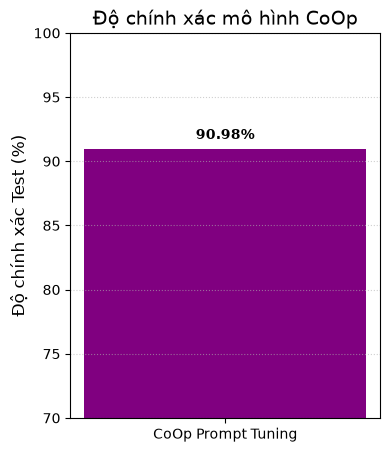

In [9]:
# Báo cáo kết quả
print("TÓM TẮT ĐỘ CHÍNH XÁC PHÂN LOẠI:")
print("-" * 50)
print(f"CoOp Prompt Tuning:              {acc_coop:.2f}%")
print("-" * 50)

# Trực quan hoá
methods = ['CoOp Prompt Tuning']
accuracies = [acc_coop]

plt.figure(figsize=(4, 5))
bars = plt.bar(methods, accuracies, color=['purple'], width=0.3)
plt.title('Độ chính xác mô hình CoOp', fontsize=14)
plt.ylabel('Độ chính xác Test (%)', fontsize=12)
plt.ylim(70, 100)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.savefig('coop_prompt_tuning_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


In [10]:
# Đo độ trễ suy diễn (Inference Latency)
print("Đang thực hiện đo đạc Latency...")

model_coop.to(device)
latencies = []
for i in range(100):
    start = time.perf_counter()
    with torch.no_grad():
        test_img = test_features[i:i+1].to(device)
        logits = model_coop(test_img, coop_input_ids)
        preds = logits.argmax(dim=-1)
    end = time.perf_counter()
    latencies.append((end - start) * 1000)

print(f"Thiết bị: {device}")
print(f"  Trung bình (Mean): {np.mean(latencies):.4f} ms")
print(f"  Phân vị p50 (Median): {np.percentile(latencies, 50):.4f} ms")
print(f"  Phân vị p95: {np.percentile(latencies, 95):.4f} ms")
print(f"  Phân vị p99: {np.percentile(latencies, 99):.4f} ms")

latencies_cpu = []
model_coop_cpu = model_coop.cpu()
test_features_cpu = test_features.cpu()
coop_input_ids_cpu = coop_input_ids.cpu()
for i in range(100):
    start = time.perf_counter()
    with torch.no_grad():
        test_img = test_features_cpu[i:i+1]
        logits = model_coop_cpu(test_img, coop_input_ids_cpu)
        preds = logits.argmax(dim=-1)
    end = time.perf_counter()
    latencies_cpu.append((end - start) * 1000)

print(f"Thiết bị: CPU")
print(f"  Trung bình (Mean): {np.mean(latencies_cpu):.4f} ms")
print(f"  Phân vị p50 (Median): {np.percentile(latencies_cpu, 50):.4f} ms")
print(f"  Phân vị p95: {np.percentile(latencies_cpu, 95):.4f} ms")
print(f"  Phân vị p99: {np.percentile(latencies_cpu, 99):.4f} ms")


Đang thực hiện đo đạc Latency...
Thiết bị: mps
  Trung bình (Mean): 66.4507 ms
  Phân vị p50 (Median): 66.4769 ms
  Phân vị p95: 68.8049 ms
  Phân vị p99: 71.2491 ms
Thiết bị: CPU
  Trung bình (Mean): 113.6158 ms
  Phân vị p50 (Median): 111.2458 ms
  Phân vị p95: 130.0733 ms
  Phân vị p99: 152.7085 ms


Tạo Ma Trận Nhầm Lẫn cho mô hình CoOp...


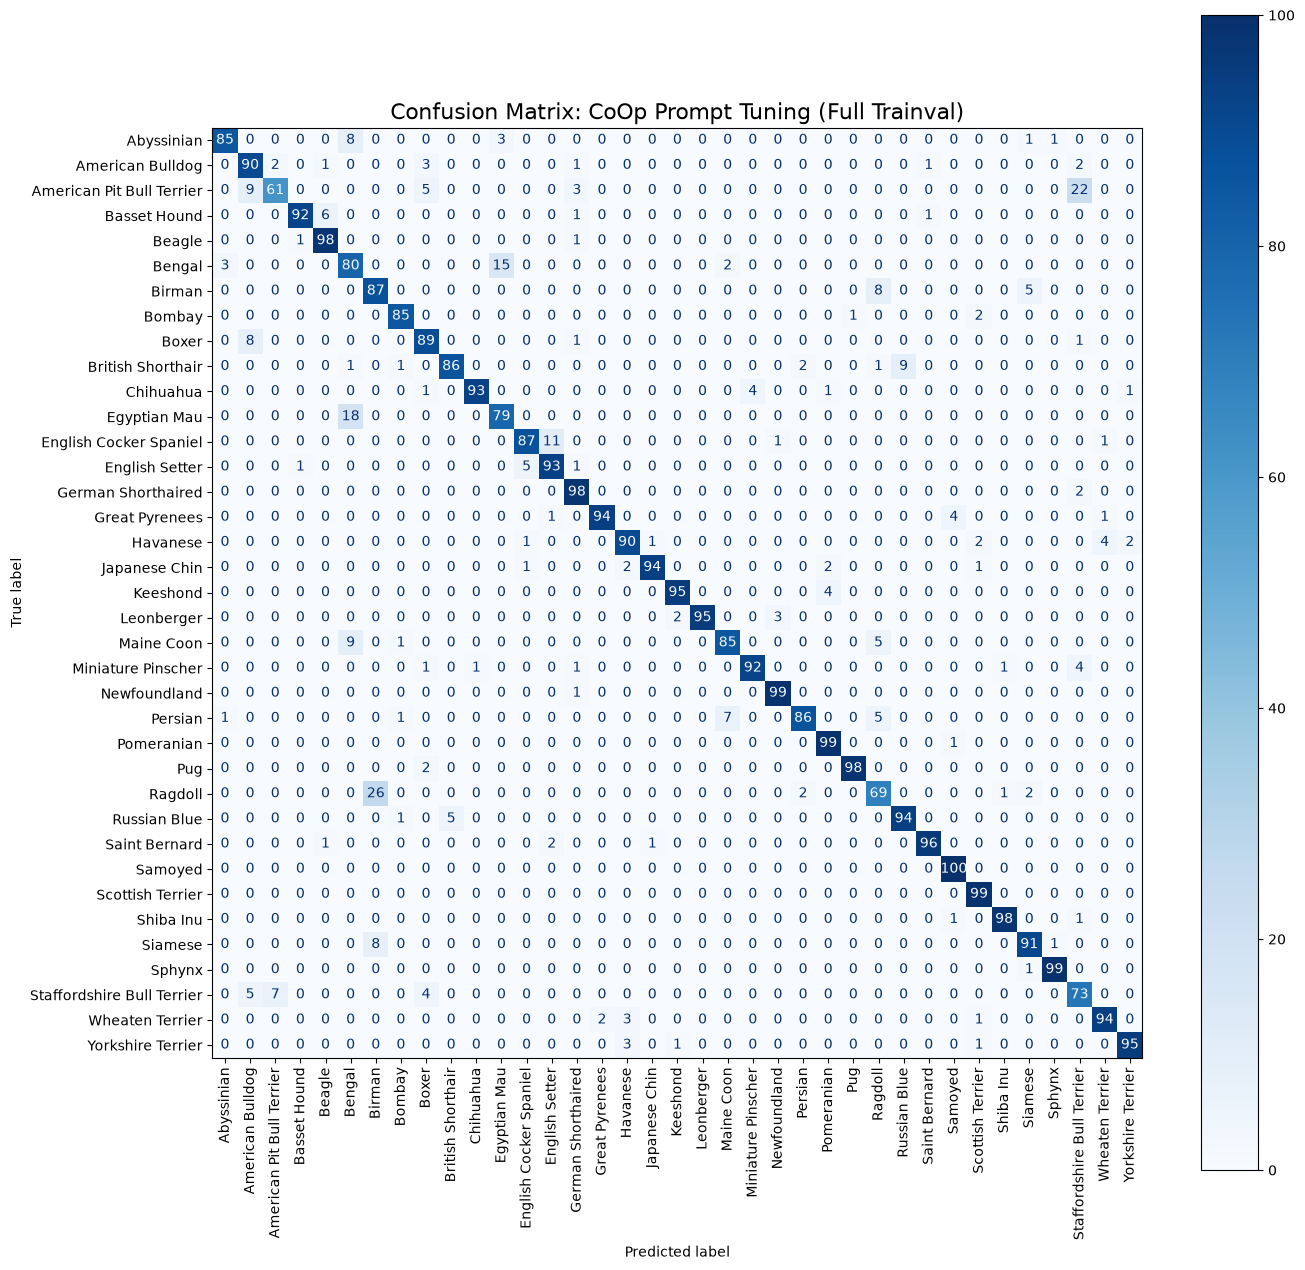

In [11]:
# Tạo ma trận nhầm lẫn (Confusion Matrix)
print("Tạo Ma Trận Nhầm Lẫn cho mô hình CoOp...")
cm = confusion_matrix(test_labels.numpy(), preds_test.cpu().numpy())

fig, ax = plt.subplots(figsize=(15, 15))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation='vertical')
plt.title("Confusion Matrix: CoOp Prompt Tuning (Full Trainval)", fontsize=16)
plt.savefig('confusion_matrix_coop_16shot.png', bbox_inches='tight', dpi=300)
plt.show()


In [12]:
# Lưu kết quả
import json
os.makedirs("results", exist_ok=True)

summary_data = {
    "coop_acc": acc_coop,
    "latency_device": {
        "device": str(device),
        "mean": float(np.mean(latencies)),
        "p50": float(np.percentile(latencies, 50)),
        "p95": float(np.percentile(latencies, 95)),
        "p99": float(np.percentile(latencies, 99))
    }
}

with open("results/summary_results_coop.json", "w") as f:
    json.dump(summary_data, f, indent=4)
    
print("Lưu file kết quả thành công tại results/summary_results_coop.json!")


Lưu file kết quả thành công tại results/summary_results_coop.json!
